# Deep Learning

## 一、感知机 Perceptron

### 1.1 感知机的概念

感知机接收多个输入信号，输出一个信号。设$x_1,x_2$为输入信号，$y$为输出信号，$w_1,w_2$为权重（weight）。输入信号被送往神经元时，会分别乘以对应的权重。当输入信号的加权总和超过了阈值$\theta$时，神经元会输出1，否则输出0。用数学式来表示，就是$$y=\begin{cases}0(w_1x_2+w_2x_2\leq\theta)\\1(w_1x_1+w_2x_2>\theta)\end{cases}\tag{1.1}$$

设偏置$b$为$-\theta$，则上式转换为齐次线性方程组$$y=\begin{cases}0(b+w_1x_2+w_2x_2\leq0)\\1(b+w_1x_1+w_2x_2>0)\end{cases}\tag{1.2}$$

### 1.2 简单逻辑电路

与门（AND gate）：有两个输入和一个输出的门电路，只有两个输入均为1时输出1，其他时候输出0。用感知机来表示只需要确定权重和阈值的值，如$(w_1,w_2,b)=(0.5,0.5,-0.7)$。

与非门（NAND gate）：仅当两个输入均为1时输出0，否则输出1。用感知机表示如$(w_1,w_2,b)=(-0.5,-0.5,0.7)$，实际上把与门参数值取相反数即可实现与非门。

或门（OR gate）：只要有一个输入信号是1，输出就为1，否则为0。用感知机表示如$(w_1,w_2,b)=(0.5,0.5,-0.2)$。

异或门（XOR gate）：仅当一个输入信号为1、另一个为0时，输出1，否则输出0。前面所述的单层感知机只能表示线性空间，因此无法实现异或门，需要通过多层感知机（multi-layer perceptron）来表示非线性空间。

下面的双层感知机可以实现异或门：

```mermaid
flowchart LR
A((x1)) -->|x1| C((NAND))
A -->|x1| D((OR))
B((x2)) -->|x2| C
B -->|x2| D
C -->|s1| E((AND))
D -->|s2| E
E -->|y| F((y))
```


In [2]:
import numpy as np

def AND(x1,x2):
    x = np.array([x1,x2])
    w = np.array([0.5,0,5])
    b = -0.7
    tmp = np.sum(w*x) + b
    if tmp <= 0:
        return 0
    else:
        return 1

def NAND(x1,x2):
    x = np.array([x1,x2])
    w = np.array([-0.5,-0,5])
    b = 0.7
    tmp = np.sum(w*x) + b
    if tmp <= 0:
        return 0
    else:
        return 1

def OR(x1,x2):
    x = np.array([x1,x2])
    w = np.array([0.5,0,5])
    b = -0.2
    tmp = np.sum(w*x) + b
    if tmp <= 0:
        return 0
    else:
        return 1

def XOR(x1,x2):
    s1 = NAND(x1,x2)
    s2 = OR(x1,x2)
    y = AND(s1,s2)
    return y

## 二、神经网络

### 2.1 神经网络的结构

神经网络由输入层、中间层（隐藏层）和输出层构成。这里把输入层称作第0层，且由于输入层没有权重，因此计算总层数时不把输入层包括在内。

设函数$$h(x)=\begin{cases}0(x\leq0)\\1(x>0)\end{cases}\tag{2.1}$$，$a=b+w_1x_1+w_2x_2$，则式$(1.2)$变为$y=h(a)$。称$h()$为激活函数（activation function）。

### 2.2 激活函数

朴素（单层）感知机使用的激活函数称为跃迁函数，如式$(2.1)$。而多层感知机（神经网络）使用的激活函数包括sigmoid函数、ReLU函数等。激活函数均为非线性函数，若使用线性函数（$h(x)=cx$），增加神经网络的层数后仍可用没有隐藏层的神经网络来表示，这样隐藏层就没有意义了。

#### 2.2.1 sigmoid函数

sigmoid函数的表达式为$$h(x)=\frac{1}{1+e^{-x}}\tag{2.2}$$

#### 2.2.2 ReLU函数

ReLU函数（Rectified Linear Unit Function）的表达式为$$h(x)=\begin{cases}x(x>0)\\0(x\leq0)\end{cases}\tag{2.3}$$

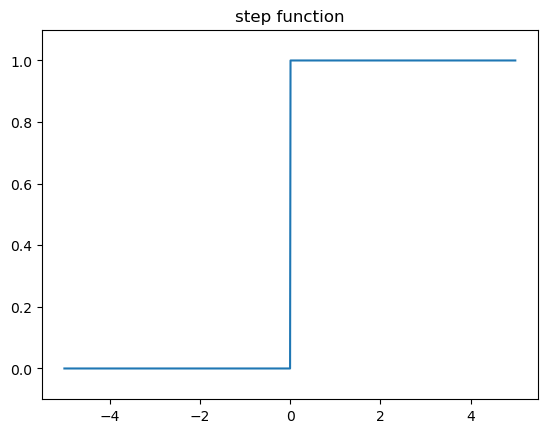

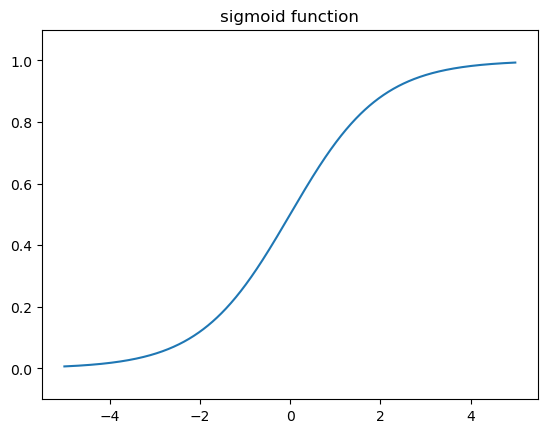

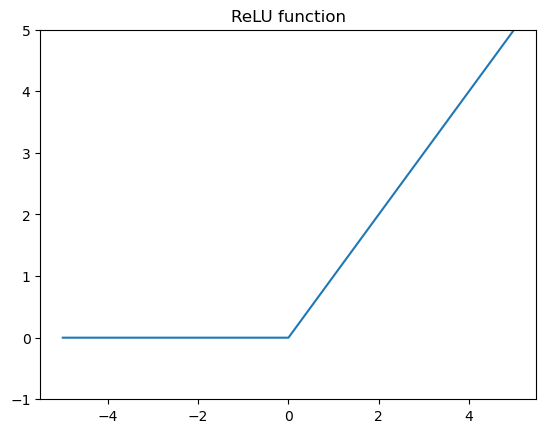

In [3]:
import matplotlib.pyplot as plt

def step_function(x):
    return np.array(x > 0, dtype=int) # numpy数组进行不等式运算时会对其中的每个元素进行不等式运算，结果为一个布尔型数组，int又将布尔值转换为整数
x = np.arange(-5.0, 5.0, 0.01)
y = step_function(x)
plt.plot(x, y)
plt.title('step function')
plt.ylim(-0.1, 1.1)
plt.show()

def sigmoid(x):
    return 1 / (1 + np.exp(-x)) # numpy数组与标量运算时，会对其中的每个元素进行该运算。
x = np.arange(-5.0, 5.0, 0.01)
y = sigmoid(x)
plt.plot(x, y)
plt.title('sigmoid function')
plt.ylim(-0.1, 1.1)
plt.show()

def relu(x):
    return np.maximum(0, x)
x = np.arange(-5.0, 5.0, 0.01)
y = relu(x)
plt.plot(x, y)
plt.title('ReLU function')
plt.ylim(-1, 5)
plt.show()

### 2.3 神经网络的实现

#### 2.3.1 使用numpy进行矩阵运算

In [4]:
A = np.array([1, 2, 3, 4])
print(A)
print(np.ndim(A)) # ndim函数获取数组的维数
print(A.shape) # 数组shape属性的类型为元组
print(type(A.shape))

B = np.array([[1,2], [3,4]])
print(B.shape)
C = np.array([[5,6], [7,8]])
print(C.shape)
print(np.dot(B, C)) # 矩阵乘法通过dot函数或@运算符实现
print(B @ C)

[1 2 3 4]
1
(4,)
<class 'tuple'>
(2, 2)
(2, 2)
[[19 22]
 [43 50]]
[[19 22]
 [43 50]]


#### 2.3.2 通过矩阵乘法进行神经网络的实现

$a_1^{(1)}$指第一层的第一个神经元，$w_{12}^{(1)}$指第一层的从输入层第二个神经元到第一层第一个神经元的权重。

设输入层的神经元个数为$m$，第一层的神经元个数为$n$，则第一层权重矩阵$\bm{W}^{(1)}$的形状为$m\times n$，偏置矩阵$\bm{B}^{(1)}$的形状为$1\times n$，输入矩阵$\bm{X}$的形状为$1\times m$，加权和矩阵$\bm{A}^{(1)}$的形状为$1\times n$。则加权和矩阵可表示为$$\bm{A}^{(1)}=\bm{X}\bm{W}^{(1)}+\bm{B}^{(1)}\tag{2.4}$$

输出层的激活函数用$\sigma()$表示，可使用恒等函数、sigmoid函数、softmax函数等。

In [5]:
# 三层神经网络的实现
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def identity_function(x):
    return x

# 第一层
X = np.array([1.0, 0.5])
W1 = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
B1 = np.array([0.1, 0.2, 0.3])
A1 = np.dot(X, W1) + B1
Z1 = sigmoid(A1)
print(Z1)

# 第二层
W2 = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
B2 = np.array([0.1, 0.2])
A2 = np.dot(Z1, W2) + B2
Z2 = sigmoid(A2)
print(Z2)

# 输出层
W3 = np.array([[0.1, 0.3], [0.2, 0.4]])
B3 = np.array([0.1, 0.2])
A3 = np.dot(Z2, W3) + B3
Y = identity_function(A3)
print(Y)

[0.57444252 0.66818777 0.75026011]
[0.62624937 0.7710107 ]
[0.31682708 0.69627909]


In [6]:
# 整理上述三层神经网络
def init_network():
    '''初始化权重和偏置矩阵，并保存至字典变量中'''
    network = {}
    network['W1'] = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
    network['b1'] = np.array([0.1, 0.2, 0.3])
    network['W2'] = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
    network['b2'] = np.array([0.1, 0.2])
    network['W3'] = np.array([[0.1, 0.3], [0.2, 0.4]])
    network['b3'] = np.array([0.1, 0.2])
    return network

def forward(network, x):
    W1, W2, W3 = network['W1'], network['W2'], network['W3']
    b1, b2, b3 = network['b1'], network['b2'], network['b3']
    a1 = np.dot(x, W1) + b1
    z1 = sigmoid(a1)
    a2 = np.dot(z1, W2) + b2
    z2 = sigmoid(a2)
    a3 = np.dot(z2, W3) + b3
    y = identity_function(a3)
    return y

network = init_network()
x = np.array([1.0, 0.5])
y = forward(network, x)
print(y)

[0.31682708 0.69627909]


### 2.4 输出层的设计

一般而言，回归问题用恒等函数，分类问题用softmax函数。

#### 2.4.1 恒等函数和softmax函数

恒等函数将输入按原样输出，即$y_k=a_k$。

softmax函数的表达式为$$y_k=\frac{e^{a_k}}{\sum^n_{i=1}e^{a_i}}\tag{2.5}$$，其中$y_k$指第$k$个神经元的输出，$a_k$为第$k$个输入信号。

但是在计算机计算过程中，指数运算可能会溢出，因此在实现softmax函数时需要进行改进：$$y_k=\frac{e^{a_k}}{\sum^n_{i=1}e^{a_i}}=\frac{Ce^{a_k}}{C\sum^n_{i=1}e^{a_i}}=\frac{e^{a_k+\log_e C}}{\sum^n_{i=1}e^{a_i+\log_e C}}$$，其中$C$为常数。这说明在进行计算时，对输入信号加上或减去某个常数不改变计算结果。为了防止溢出，一般会减去输入信号中的最大值。

In [7]:
# softmax函数的实现

def softmax(a):
    c = np.max(a)
    exp_a = np.exp(a - c) # 溢出对策
    sum_exp_a = np.sum(exp_a)
    y = exp_a / sum_exp_a
    return y

a = np.array([0.3, 2.9, 4.0])
y = softmax(a)
print(y)

[0.01821127 0.24519181 0.73659691]


softmax函数的输出是0到1之间的实数，并且输出值的总和是1。但由于指数函数是单调递增函数，a的大小关系并没有被改变。因此，在推理阶段，神经网络一般会忽略输出层的softmax函数，只把输出值最大的神经元所对应的类别作为识别结果。

#### 2.4.2 输出层的神经元数量

对于分类问题，输出层的神经元数量一般设定为类别的数量。

### 2.5 手写数字识别

MNIST数据集：0-9的数字图像，共7万张。每张图像是28像素×28像素的灰度图像，各个像素的取值在0-255之间。每个图像都标有数字标签。

神经网络的输入层有28×28=784个神经元，输出层有10个神经元。该网络有2个隐藏层，第一个隐藏层有50个神经元，第2个隐藏层有100个神经元。

sample_weight.pkl以字典变量的形式保存了权重和偏置参数。load_mnist的normalize参数对像素值进行正规化（normalization），作为对输入图像的一种预处理（prepossessing）。

若想用predict()函数一次性打包处理100张图像，可以把x的形状改为100×784，此时输出数据的形状也相应变为100×10。这种打包式的输入数据称为批（batch）。

In [8]:
import sys, os, pickle
sys.path.append(os.pardir) # 为了导入父目录中的文件而进行的设定
from assets.codes.mnist import load_mnist

def get_data():
    (x_train, t_train), (x_test, t_test) = \
        load_mnist(normalize=True, flatten=True, one_hot_label=False)
    return x_test, t_test

def init_network():
    with open(r"..\assets\codes\sample_weight.pkl", 'rb') as f:
        network = pickle.load(f)
    return network

def predict(network, x):
    W1, W2, W3 = network['W1'], network['W2'], network['W3']
    b1, b2, b3 = network['b1'], network['b2'], network['b3']

    a1 = np.dot(x, W1) + b1
    z1 = sigmoid(a1)
    a2 = np.dot(z1, W2) + b2
    z2 = sigmoid(a2)
    a3 = np.dot(z2, W3) + b3
    y = softmax(a3)
    return y

x, t = get_data()
network = init_network()

accuracy_cnt = 0
for i in range(len(x)):
    y = predict(network, x[i])
    p = np.argmax(y) # 获取概率最高的元素的索引
    if p == t[i]:
        accuracy_cnt += 1

print("Accuracy:" + str(float(accuracy_cnt) / len(x)))

# 基于批处理的代码实现
x, t = get_data()
network = init_network()
batch_size = 100 # 批数量
accuracy_cnt = 0
for i in range(0, len(x), batch_size):
    x_batch = x[i:i+batch_size]
    y_batch = predict(network, x_batch)
    p = np.argmax(y_batch, axis=1) #二维数组的第0维是列方向，第1维是行方向。
    accuracy_cnt += np.sum(p == t[i:i+batch_size]) #p == t[i:i+batch_size]得到布尔型数组，sum将其转换为数值后求和
print("Accuracy:" + str(float(accuracy_cnt) / len(x)))

C:\Users\31653\AppData\Local\Temp\ipykernel_16468\994368444.py:12: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  network = pickle.load(f)


Accuracy:0.9352
Accuracy:0.9352


## 三、神经网络的学习

对于图像识别，机器学习需要预先设计特征量的提取算法，然后对特征量进行机器学习，而深度学习可以直接对原始数据进行学习。因此，深度学习有时也称为端到端机器学习。

### 3.1 损失函数

损失函数是表示神经网络性能“差的程度”的指标，一般使用均方误差和交叉熵误差等。

#### 3.1.1 均方误差

均方误差（mean squared error, MSE）的表达式为$$E=\frac{1}{2}\sum_k(y_k-t_k)^2\tag{3.1}$$，其中$y_k$为神经网络的输出，$t_k$为训练数据（监督数据），$t_k$使用独热表示，如$[0,0,1,0,0,0,0,0,0,0]$表示正确解为“2”，$k$为数据的维数。

In [9]:
def mean_squared_error(y, t):
    return 0.5 * np.sum((y-t)**2)

# 设“2”为正确解
t = [0, 0, 1, 0, 0, 0, 0, 0, 0, 0]

# 例1：“2”的概率最高的情况（0.6）
y = [0.1, 0.05, 0.6, 0.0, 0.05, 0.1, 0.0, 0.1, 0.0, 0.0]
print(mean_squared_error(np.array(y), np.array(t)))

# 例2：“7”的概率最高的情况（0.6）
y = [0.1, 0.05, 0.1, 0.0, 0.05, 0.1, 0.0, 0.6, 0.0, 0.0]
print(mean_squared_error(np.array(y), np.array(t)))

0.09750000000000003
0.5975


#### 3.1.2 交叉熵误差

交叉熵误差（cross entropy error）的表达式为$$E=-\sum_k t_k \log_e y_k\tag{3.2}$$，因此上式只计算对应正确解的输出的自然对数。正确解标签标签对应的输出越大，上式的值越接近0。

在实现时，会给对数计算加上一个微小值，避免出现负无穷。

In [10]:
def cross_entropy_error(y, t):
    delta = 1e-7
    return -np.sum(t * np.log(y + delta))

t = [0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
y = [0.1, 0.05, 0.6, 0.0, 0.05, 0.1, 0.0, 0.1, 0.0, 0.0]
print(cross_entropy_error(np.array(y), np.array(t)))

y = [0.1, 0.05, 0.1, 0.0, 0.05, 0.1, 0.0, 0.6, 0.0, 0.0]
print(cross_entropy_error(np.array(y), np.array(t)))

0.510825457099338
2.302584092994546


#### 3.1.3 小批量学习

若要求所有训练数据的平均损失函数，以交叉熵误差为例，其表达式为$$E=-\frac{1}{N}\sum_n\sum_k t_{nk} \log_e y_{nk}$$，其中$N$为数据总数，$t_{nk}$表示第$n$个数据的第$k$个元素的值。

在神经网络的学习中，数据量会达千万、亿级别，在这种情况下对全部数据计算损失函数会耗费较长时间。因此，可以从全部数据中选出一部分，作为全部数据的近似，这种方法称为小批量（mini-batch）学习。



In [11]:
(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, one_hot_label=True)
print(x_train.shape) # (60000, 784)
print(t_train.shape) # (60000, 10)

train_size = x_train.shape[0]
batch_size = 10
batch_mask = np.random.choice(train_size, batch_size)
x_batch = x_train[batch_mask]
t_batch = t_train[batch_mask]

def cross_entropy_error(y, t):
    if y.ndim == 1:
        t = t.reshape(1, t.size)
        y = y.reshape(1, y.size)
    batch_size = y.shape[0]
    return -np.sum(t * np.log(y + 1e-7)) / batch_size # *为对应位置元素相乘的运算符

# 当监督数据是标签形式时，可通过以下函数实现
def cross_entropy_error_2(y, t):
    if y.ndim == 1:
        t = t.reshape(1, t.size) # 将一维数组变为二维数组
        y = y.reshape(1, y.size)
    batch_size = y.shape[0]
    return -np.sum(np.log(y[np.arange(batch_size), t] + 1e-7)) / batch_size
# np.arange(batch_size)生成一个从0到batch_size-1的数组
# [np.arange(batch_size), t]会生成一个二维数组，如[0,2], [1,7], [2,0]，由此实现每一行取出正确标签。

(60000, 784)
(60000, 10)


### 3.2 梯度法

#### 3.2.1 数值微分

数值微分（numerical differentiation）指用数值方法近似求解函数导数的过程。中心差分以某处为中心，计算它左右两边的差分，即$$\frac{\mathrm{d} f(x)}{\mathrm{d} x}=\lim_{h\to0}\frac{f(x+h)-f(x-h)}{2h}\tag{3.3}$$。不同于解析性求导，数值微分总会有误差，但误差非常小。

#### 3.2.2 梯度

梯度（gradient）是一个由偏导数组成的向量，它指向多元函数在某点上“增长最快的方向”，其长度表示该方向上的最大变化率。对于多元可微函数$f(x_1,x_2,\cdots,x_n)$，梯度定义为：$$\nabla f=(\frac{\partial f}{\partial x_1},\frac{\partial f}{\partial x_2},\cdots,\frac{\partial f}{\partial x_n})$$，其中$\nabla$为梯度运算符，全拼为nabla。

In [12]:
def numerical_gradient_1d(f, x):
    h = 1e-4 # 0.0001
    grad = np.zeros_like(x) # 生成和x形状相同的全零数组
    for idx in range(x.size):
        tmp_val = x[idx]
        # f(x+h) 的计算
        x[idx] = tmp_val + h
        fxh1 = f(x)
        # f(x-h) 的计算
        x[idx] = tmp_val - h
        fxh2 = f(x)
        grad[idx] = (fxh1 - fxh2) / (2*h)
        x[idx] = tmp_val # 还原值
    return grad

def function_2(x):
    return np.sum(x**2)

print(numerical_gradient_1d(function_2, np.array([3.0, 4.0]))) # numpy数组打印时会将数值四舍五入
print(numerical_gradient_1d(function_2, np.array([0.0, 2.0])))
print(numerical_gradient_1d(function_2, np.array([3.0, 0.0])))

[6. 8.]
[0. 4.]
[6. 0.]


#### 3.2.3 梯度下降法

寻找最小值的梯度法称为梯度下降法，寻找最大值的梯度法称为梯度上升法。在深度学习中，梯度法主要指梯度下降法。在梯度下降法中，函数的取值从当前位置沿着梯度方向前进一定距离，然后在新的地方重新求梯度，再沿着新梯度方向前进，如此循环。每次更新用数学式表示为：$$\bm{x'}=\bm{x}-\bm{\eta}\nabla f\tag{3.4}$$其中$\bm{\eta}$称为学习率（learning rate），它决定在一次学习中要学习多少，以及在多大程度上更新参数。在学习中，需要事先确定为某个值，比如0.01或0.001，同时一般会一边改变学习率的值，一边确认学习是否正确进行了。

像学习率这样的参数称为超参数（hyperparameter），相较于权重、偏置等通过学习自动获得的参数，超参数则是人工设定的。一般来说，超参数需要尝试多个值，以便找到一种可以使学习顺利进行的设定。

梯度的方向并不一定指向最小值，但沿着它的方向能够最大限度地减小函数的值。当函数很复杂且呈扁平状时，学习可能会进入被称为“学习高原”的停滞期。

In [13]:
# 用梯度下降法求f(x0+x1)=x0^2+x1^2的最小值
def function_1(x):
    return np.sum(x ** 2)

def gradient_descent(f, x, lr=0.01, n=100):
    for _ in range(n):
        x = x - lr * numerical_gradient_1d(f, x)
    return x

print(gradient_descent(function_1, np.array([-3.0, 4.0]), 0.1, 100))

[-6.11110793e-10  8.14814391e-10]


#### 3.2.4 神经网络的梯度

神经网络的梯度只损失函数关于权重参数的梯度。比如，对于权重$\bm{W}_{2\times3}$和损失函数$L$，有$$\frac{\partial L}{\partial \bm{W}}=\begin{pmatrix}\frac{\partial L}{\partial \bm{w_{11}}}&\frac{\partial L}{\partial \bm{w_{12}}}&\frac{\partial L}{\partial \bm{w_{13}}}\\\frac{\partial L}{\partial \bm{w_{21}}}&\frac{\partial L}{\partial \bm{w_{22}}}&\frac{\partial L}{\partial \bm{w_{23}}}\end{pmatrix}\tag{3.5}$$

In [14]:
class simpleNet:
    def __init__(self):
        self.W = np.random.randn(2,3) # 用正态分布进行初始化
    def predict(self, x):
        return np.dot(x, self.W)
    def loss(self, x, t):
        z = self.predict(x)
        y = softmax(z)
        loss = cross_entropy_error(y, t)
        return loss

def numerical_gradient(f, x):
    h = 1e-4 # 0.0001
    grad = np.zeros_like(x)
    
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        idx = it.multi_index
        tmp_val = x[idx]
        x[idx] = float(tmp_val) + h
        fxh1 = f(x) # f(x+h)
        
        x[idx] = tmp_val - h 
        fxh2 = f(x) # f(x-h)
        grad[idx] = (fxh1 - fxh2) / (2*h)
        
        x[idx] = tmp_val # 还原值
        it.iternext()   
        
    return grad

net = simpleNet()
print(net.W) # 初始权重矩阵
x = np.array([0.6, 0.9]) # 输入矩阵
t = np.array([0, 0, 1]) # 正确解标签
print(net.loss(x, t))
f = lambda w: net.loss(x, t) # 隐函数，避免执行f(x)时变量数不匹配
dW = numerical_gradient(f, net.W)
print(dW)

[[-1.12932178  1.07299666  0.7678708 ]
 [-0.14733532  0.96742827 -1.92303239]]
2.93254220832541
[[ 0.05061234  0.51742977 -0.56804211]
 [ 0.07591852  0.77614466 -0.85206317]]


观察dW的值，如$\frac{\partial L}{\partial w_{11}}$的值约为0.3，$\frac{\partial L}{\partial w_{23}}$的值约为-0.5。因此，$w_{11}$应该向负方向更新、$w_{23}$向正方向更新，以减小损失函数值。对于更新的程度，$w_{23}$要比$w_{11}$的贡献大。

### 3.3 学习算法的实现

随机梯度下降法（stochastic gradient descent, SGD）步骤：
1. 从训练数据中随机选出mini-batch，目标是减小mini-batch损失函数的值。
2. 计算各个权重参数对于损失函数的梯度，梯度为损失函数值增长最快的方向。
3. 将权重参数沿梯度的反方向进行更新。
4. 重复上述步骤。

这里以2层神经网络（隐藏层为1层的网络）为对象，使用MNIST数据集进行学习。

train acc, test acc | 0.1035, 0.1031
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.10441666666666667, 0.1028
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.10441666666666667, 0.1028
train acc, test acc | 0.11236666666666667, 0.1135
train acc, test acc | 0.11236666666666667, 0.1135


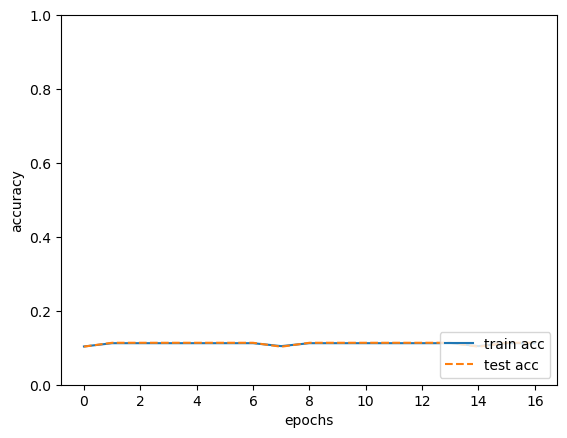

In [15]:
def sigmoid_grad(x):
    return (1.0 - sigmoid(x)) * sigmoid(x)

class TwoLayerNet:

    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01):
        # 初始化权重
        self.params = {}
        self.params['W1'] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params['b1'] = np.zeros(hidden_size)
        self.params['W2'] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params['b2'] = np.zeros(output_size)

    def predict(self, x):
        W1, W2 = self.params['W1'], self.params['W2']
        b1, b2 = self.params['b1'], self.params['b2']
    
        a1 = np.dot(x, W1) + b1
        z1 = sigmoid(a1)
        a2 = np.dot(z1, W2) + b2
        y = softmax(a2)
        
        return y
        
    # x:输入数据, t:监督数据
    def loss(self, x, t):
        y = self.predict(x)
        
        return cross_entropy_error(y, t)
    
    def accuracy(self, x, t):
        y = self.predict(x)
        y = np.argmax(y, axis=1)
        t = np.argmax(t, axis=1)
        
        accuracy = np.sum(y == t) / float(x.shape[0])
        return accuracy
        
    # x:输入数据, t:监督数据
    def numerical_gradient(self, x, t):
        loss_W = lambda W: self.loss(x, t)
        
        grads = {}
        grads['W1'] = numerical_gradient(loss_W, self.params['W1'])
        grads['b1'] = numerical_gradient(loss_W, self.params['b1'])
        grads['W2'] = numerical_gradient(loss_W, self.params['W2'])
        grads['b2'] = numerical_gradient(loss_W, self.params['b2'])
        
        return grads
        
    def gradient(self, x, t):
        W1, W2 = self.params['W1'], self.params['W2']
        b1, b2 = self.params['b1'], self.params['b2']
        grads = {}
        
        batch_num = x.shape[0]
        
        # forward
        a1 = np.dot(x, W1) + b1
        z1 = sigmoid(a1)
        a2 = np.dot(z1, W2) + b2
        y = softmax(a2)
        
        # backward
        dy = (y - t) / batch_num
        grads['W2'] = np.dot(z1.T, dy)
        grads['b2'] = np.sum(dy, axis=0)
        
        da1 = np.dot(dy, W2.T)
        dz1 = sigmoid_grad(a1) * da1
        grads['W1'] = np.dot(x.T, dz1)
        grads['b1'] = np.sum(dz1, axis=0)

        return grads

# 读入数据
(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, one_hot_label=True)

network = TwoLayerNet(input_size=784, hidden_size=50, output_size=10)

iters_num = 10000  # 适当设定循环的次数
train_size = x_train.shape[0]
batch_size = 100
learning_rate = 0.1

train_loss_list = []
train_acc_list = []
test_acc_list = []

iter_per_epoch = max(train_size / batch_size, 1)

for i in range(iters_num):
    batch_mask = np.random.choice(train_size, batch_size)
    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]
    
    # 计算梯度
    #grad = network.numerical_gradient(x_batch, t_batch)
    grad = network.gradient(x_batch, t_batch)
    
    # 更新参数
    for key in ('W1', 'b1', 'W2', 'b2'):
        network.params[key] -= learning_rate * grad[key]
    
    loss = network.loss(x_batch, t_batch)
    train_loss_list.append(loss)
    
    if i % iter_per_epoch == 0:
        train_acc = network.accuracy(x_train, t_train)
        test_acc = network.accuracy(x_test, t_test)
        train_acc_list.append(train_acc)
        test_acc_list.append(test_acc)
        print("train acc, test acc | " + str(train_acc) + ", " + str(test_acc))

# 绘制图形
markers = {'train': 'o', 'test': 's'}
x = np.arange(len(train_acc_list))
plt.plot(x, train_acc_list, label='train acc')
plt.plot(x, test_acc_list, label='test acc', linestyle='--')
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.ylim(0, 1.0)
plt.legend(loc='lower right')
plt.show()

在深度学习中，epoch的单位是“完整遍历一次训练数据集”。批次大小（Batch Size）：一次训练中选取的样本数量。关系公式：循环数（Iteration） = 训练集样本总数 ÷ 批次大小。完成所有循环后，整个训练集被遍历一次，即完成一个epoch。

一般做法是事先将所有训练数据随机打乱，然后按指定的批次大小，按序生成mini-batch。这样每个mini-batch均有一个索引号，然后用索引号可以遍历所有的mini-batch。但本节中的mini-batch每次都是随机选择的，所以不一定每个数据都会被看到。

神经网络的学习中，必须确认是否能够正确识别训练数据以外的其他数据，即确认是否会发生过拟合。在上面的例子中，每经过一个epoch，就对所有的训练数据和测试数据计算识别精度，并记录结果。之所以要计算每一个epoch的识别精度，是因为如果在for语句的循环中一直计算识别精度，会花费太多时间。

如图所示，随着epoch的增加，训练数据和测试数据评价的识别精度都提高了，并且这两个识别精度基本上没有差异（两
条线基本重叠在一起）。因此，可以说这次的学习中没有发生过拟合的现象。

## 四、误差反向传播法

### 4.1 链式法则

定义：如果某个函数由复合函数表示，则该复合函数的导数可以用构成复合函数的各个函数的导数的乘积表示。

例如，对于复合函数$z=(x+y)^2$，设$t=x+y$，则$z=t^2$，有$$\frac{\partial z}{\partial x}=\frac{\partial z}{\partial t}\frac{\partial t}{\partial x}=2t\cdot1=2(x+y)$$

### 4.2 反向传播

反向传播基于链式法则。若要求$\frac{\partial z}{\partial x}$，可通过$\frac{\partial z}{\partial z}\frac{\partial z}{\partial t}\frac{\partial t}{\partial x}$得到。

加法节点的反向传播将上游的值原封不动地输出到下游，因为对于$z=x+y$，$\frac{\partial z}{\partial x}$和$\frac{\partial z}{\partial y}$均为1。

乘法节点的反向传播会将上游的值乘以正向传播时的输入信号的另一个值后传递给下游。因为对于$z=x+y$，$\frac{\partial z}{\partial x}=y$，$\frac{\partial z}{\partial y}=x$。因此乘法节点需要保存输入信号的值。

#### 4.2.1 加法层和乘法层的实现

这里把神经网络中功能的单位称为层，如加法层（AddLayer）、乘法层（MulLayer）、Sigmoid层、Affine层等，每个层都将实现为一个类，共享两个方法：forward()和backwoard()。

In [16]:
# 乘法层
class MulLayer:

    def __init__(self):
        self.x, self.y = None, None # 用于保存正向传播的输入值

    def forward(self, x, y):
        self.x, self.y = x, y
        return x * y
    
    def backward(self, dout): # dout为上游传来的导数
        return dout * self.y, dout * self.x

apple = 100
apple_num = 2
tax = 1.1

# 对两个乘法层进行初始化
mul_apple_layer = MulLayer()
mul_tax_layer = MulLayer()

# 前向传播
apple_price = mul_apple_layer.forward(apple, apple_num)
price = mul_tax_layer.forward(apple_price, tax)
print(price)

# 反向传播
dprice = 1
dapple_price, dtax = mul_tax_layer.backward(dprice)
dapple, dapple_num = mul_apple_layer.backward(dapple_price)
print(dapple, dapple_num, dtax)

220.00000000000003
2.2 110.00000000000001 200


In [17]:
# 加法层
class AddLayer:

    def __init__(self):
        pass

    def forward(self, x, y):
        return x + y
    
    def backward(self, dout):
        return dout, dout

apple = 100
apple_num = 2
orange = 150
orange_num = 3
tax = 1.1

mul_apple_layer = MulLayer()
mul_orange_layer = MulLayer()
mul_tax_layer = MulLayer()
add_apple_orange_layer = AddLayer()

# 前向传播
apple_price = mul_apple_layer.forward(apple, apple_num)
orange_price = mul_orange_layer.forward(orange, orange_num)
apple_orange_price = add_apple_orange_layer.forward(apple_price, orange_price)
price = mul_tax_layer.forward(apple_orange_price, tax)

# 反向传播
dprice = 1
dapple_orange_price, dtax = mul_tax_layer.backward(dprice)
dapple_price, dorange_price = add_apple_orange_layer.backward(dapple_orange_price)
dapple, dapple_num = mul_apple_layer.backward(dapple_price)
dorange, dorange_num = mul_orange_layer.backward(dorange_price)
print(dapple, dapple_num, dorange, dorange_num, dtax)

2.2 110.00000000000001 3.3000000000000003 165.0 650


#### 4.2.2 ReLU层的实现

激活函数ReLU的表达式为$$y=\begin{cases}x(x>0)\\0(x\leq0)\end{cases}$$，则$y$关于$x$的导数表达式为$$\frac{\partial y}{\partial x}=\begin{cases}1(x>0)\\0(x\leq0)\end{cases}$$即若正向传播时的输入大于0，反向传播会将上游的值原封不动地传给下游；若小于等于0，则反向传播中传给下游的信号将停在此处。

In [18]:
# ReLU层的实现
class Relu:

    def __init__(self):
        self.mask = None

    def forward(self, x):
        self.mask = (x <= 0)
        out = x.copy()
        out[self.mask] = 0 # 将在mask中所有值为True的位置赋值为0
    
    def backward(self, dout):
        dout[self.mask] = 0
        dx = dout
        return dx

#### 4.2.3 Sigmoid层的实现

sigmoid函数的表达式为$$y=\frac{1}{1+e^{-x}}$$，对$x$求导得$$\frac{\rm{d}y}{\rm{d}x}=\frac{e^{-x}}{(1+e^{-x})^2}=y^2e^{-x}=y^2(\frac{1}{y}-1)=y(1-y)$$，因此sigmoid层的反向传播可以根据正向传播的输出值计算。

In [19]:
class Sigmoid:

    def __init__(self):
        self.out = 0

    def forward(self, x):
        out = 1 / (1 + np.exp(-x))
        self.out = out
        return out
    
    def backward(self, dout):
        dx = dout * (1.0 - self.out) * self.out
        return dx

#### 4.2.4 仿射层的实现

现在考虑矩阵的乘积运算，每一层都经过以下运算$$\bm{Y}=\bm{X}\cdot\bm{W}+\bm{B}$$，由于矩阵乘法在几何中被称为仿射（Affine, /əˈfaɪn/），因此也将进行仿射变换的层称为仿射层。设损失函数为$L$，则有$$\frac{\partial L}{\partial \bm{X}}=\frac{\partial L}{\partial \bm{Y}}\cdot\bm{W}^\top\\\;\\\frac{\partial L}{\partial \bm{W}}=\bm{X}^\top\cdot\frac{\partial L}{\partial \bm{Y}}\\\;\\\frac{\partial L}{\partial \bm{B}}=\frac{\partial L}{\partial \bm{Y}}$$对于批版本的仿射层，$\bm{X}$和$\bm{Y}$的行数都会从1增加到$N$，尽管$\bm{B}$的形状不变（1行），但在前向传播时会加到每一行（每个数据）上。因此，反向传播时，各个数据反向传播的值需要沿着第0轴汇总为偏置的元素。

In [20]:
class Affine:

    def __init__(self, W, b):
        self.W = W
        self.b = b
        self.x = None
        self.dW = None
        self.db = None

    def forward(self, x):
        self.x = x
        out = np.dot(x, self.W) + self.b
        return out
    
    def backward(self, dout):
        dx = np.dot(dout, self.W.T)
        self.dW = np.dot(self.x.T, dout)
        self.db = np.sum(dout, axis=0)
        return dx

#### 4.2.5 Softmax层的实现

神经网络中进行的处理有推理（inference）和学习两个阶段。神经网络的推理通常不使用Softmax层，将最后一个Affine层的输出作为识别结果。神经网络中未被正规化的输出结果有时
被称为“得分”。也就是说，当神经网络的推理只需要给出一个答案的情况下，因为此时只对得分最大值感兴趣，所以不需要Softmax层。不过，神经网络的学习阶段则需要Softmax层。

使用交叉熵误差作为softmax函数的损失函数后，反向传播得到
$(y_1−t_1,y_2−t_2,y_3−t_3)$这样“漂亮”的结果。实际上，这样“漂亮”的结果并不是偶然的，而是为了得到这样的结果，特意设计了交叉熵误差函数。回归问题中输出层使用恒等函数，损失函数使用平方和误差，也是出于同样的理由。

In [21]:
class SoftmaxWithLoss:

    def __init__(self):
        self.loss = None # 损失
        self.y = np.array([])    # softmax的输出
        self.t = np.array([])    # 监督数据（one-hot vector）

    def forward(self, x, t):
        self.t = t
        self.y = softmax(x)
        self.loss = cross_entropy_error(self.y, self.t)
        return self.loss

    def backward(self, dout=1):
        batch_size = self.t.shape[0]
        dx = (self.y - self.t) / batch_size # 单个数据的平均误差
        return dx

### 4.3 误差反向传播法的实现

OrderedDict是有序字典，“有序”是指它可以记住向字典里添加元素的顺序。因此，神经网络的正向传播只需按照添加元素的顺序调用各层的forward()方法就可以完成处理，而反向传播只需要按照相反的顺序调用各层即可。

In [ ]:
from collections import OrderedDict

class TwoLayerNet:

    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01):
        
        # 初始化权重
        self.params = {}
        self.params['W1'] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params['b1'] = np.zeros(hidden_size)
        self.params['W2'] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params['b2'] = np.zeros(output_size)
        
        # 生成层
        self.layers = OrderedDict()
        self.layers['Affine1'] = Affine(self.params['W1'], self.params['b1'])
        self.layers['Relu1'] = Relu()
        self.layers['Affine2'] = Affine(self.params['W2'], self.params['b2'])
        self.lastLayer = SoftmaxWithLoss()

    def predict(self, x):
        for layer in self.layers.values():
            x = layer.forward(x)
        return x
    
    def loss(self, x, t):
        y = self.predict(x)
        return self.lastLayer.forward(y, t)
    
    def accuracy(self, x, t):
        y = self.predict(x)
        y = np.argmax(y, axis=1)
        if t.ndim != 1 : t = np.argmax(t, axis=1)
        accuracy = np.sum(y == t) / float(x.shape[0])
        return accuracy

    def numerical_gradient(self, x, t):
        loss_W = lambda W: self.loss(x, t)
        grads = {}
        grads['W1'] = numerical_gradient(loss_W, self.params['W1'])
        grads['b1'] = numerical_gradient(loss_W, self.params['b1'])
        grads['W2'] = numerical_gradient(loss_W, self.params['W2'])
        grads['b2'] = numerical_gradient(loss_W, self.params['b2'])
        return grads
    
    def gradient(self, x, t):

        # forward
        self.loss(x, t)

        # backward
        dout = 1
        dout = self.lastLayer.backward(dout)
        layers = list(self.layers.values())
        layers.reverse()
        for layer in layers:
            dout = layer.backward(dout)

        # 设定
        grads = {}
        grads['W1'] = self.layers['Affine1'].dW
        grads['b1'] = self.layers['Affine1'].db
        grads['W2'] = self.layers['Affine2'].dW
        grads['b2'] = self.layers['Affine2'].db
        
        return grads


#### 4.3.1 梯度确认

数值微分的优点是实现简单，因此，一般情况下不太容易出错。而误差反向传播法的实现很复杂，容易出错。所以，经常会比较数值微分的结果和误差反向传播法的结果，以确认误差反向传播法的实现是否正确。确认数值微分求出的梯度结果和误差反向传播法求出的结果是否非常相近的操作称为梯度确认（gradient check）。

In [ ]:
# 读入数据
(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, one_hot_label = True)
network = TwoLayerNet(input_size=784, hidden_size=50, output_size=10)
x_batch = x_train[:3]
t_batch = t_train[:3]
grad_numerical = network.numerical_gradient(x_batch, t_batch)
grad_backprop = network.gradient(x_batch, t_batch)

# 求各个权重的绝对误差的平均值
for key in grad_numerical.keys():
    diff = np.average( np.abs(grad_backprop[key] - grad_numerical[key]) )
    print(key + ":" + str(diff))

TypeError: unsupported operand type(s) for *: 'NoneType' and 'float'

## 五、与学习相关的技巧

### 5.1 参数的更新

#### 5.1.1 随机梯度下降法的缺点

如果函数的形状是各向异性的，比如呈延伸状，梯度的方向就不指向最小值，搜索的路径就会非常低效。

#### 5.1.2 动量法

动量法（Momentum method）用数学式表示为$$\begin{align}\bm{v'}&=\alpha\bm{v}-\eta\frac{\partial L}{\partial\bm{W}}\\\bm{W'}&=\bm{W}+\bm{v'}\end{align}\tag{5.1}$$



In [28]:
class Momentum:
    def __init__(self, lr=0.01, momentum=0.9):
        self.lr = lr
        self.momentum = momentum
        self.v = None

def update(self, params, grads):
    if self.v is None:
        self.v = {}
        for key, val in params.items():
            self.v[key] = np.zeros_like(val)

    for key in params.keys():
        self.v[key] = self.momentum*self.v[key] - self.lr*grads[key]
        params[key] += self.v[key]

相较于SGD，动量法增加了一项$\alpha\bm{v}$，$\alpha$一般设定为0.9等值，代表了历史梯度的指数加权平均。因此，动量法具有记忆能力，每次更新依赖历史梯度。如果过去几步的梯度方向一致，动量会不断累加，使得步伐越来越大，从而大大加快收敛速度；如果方向相反，动量会相互抵消。对于“峡谷”地形，由于震荡的方向经常是正负交替的，在累加求平均时，左右震荡的动量会相互抵消；而一直向谷底前进的方向始终一致，向前的动量会不断累加。因此，动量法能有效抑制震荡，让参数快速地滑向最低点。同时，动量法可以依靠累积的动量，冲出较浅的局部极小值，继续寻找全局更优解。

#### 5.1.3 AdaGrad

AdaGrad（Adaptive Gradient，自适应梯度法）会在学习过程中为参数的每个元素适当地调整学习率，用数学式表示为$$\begin{aligned}\bm{h}&=\bm{h}+\frac{\partial L}{\partial \bm{W}}\odot\frac{\partial L}{\partial \bm{W}}\\\bm{W'}&=\bm{W}-\eta\frac{1}{\sqrt{\bm{h}}}\frac{\partial L}{\partial \bm{W}}\end{aligned}\tag{5.2}$$，其中$\odot$为Hadamard积，指两个同形矩阵对应位置元素的逐一相乘。$\bm{h}$保存了历史梯度的平方和，因此$\frac{1}{\sqrt{\bm{h}}}$项会将变动较大元素的学习率大幅变小。

但是，随着学习深入，所有元素更新的幅度都会越来越小，直到完全不更新。为了解决这个问题，可以使用RMSProp方法，该方法逐渐地遗忘过去的梯度，将新梯度的信息更多地反映出来。

In [29]:
class AdaGrad:
    def __init__(self, lr=0.01):
        self.lr = lr
        self.h = None

def update(self, params, grads):
    if self.h is None:
        self.h = {}

    for key, val in params.items():
        self.h[key] = np.zeros_like(val)

    for key in params.keys():
        self.h[key] += grads[key] * grads[key]
        params[key] -= self.lr * grads[key] / (np.sqrt(self.h[key]) + 1e-7) # 加上微小值以防除0

#### 5.1.4 Adam法

Adam方法融合了前两个方法的优点，同时还进行了超参数的偏置校正。

In [30]:
class Adam:

    """Adam (http://arxiv.org/abs/1412.6980v8)"""

    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999):
        self.lr = lr
        self.beta1 = beta1 # 一次动量系数
        self.beta2 = beta2 # 二次动量系数
        self.iter = 0
        self.m = None
        self.v = None
        
    def update(self, params, grads):
        if self.m is None:
            self.m, self.v = {}, {}
            for key, val in params.items():
                self.m[key] = np.zeros_like(val)
                self.v[key] = np.zeros_like(val)
        
        self.iter += 1
        lr_t  = self.lr * np.sqrt(1.0 - self.beta2**self.iter) / (1.0 - self.beta1**self.iter)         
        
        for key in params.keys():
            #self.m[key] = self.beta1*self.m[key] + (1-self.beta1)*grads[key]
            #self.v[key] = self.beta2*self.v[key] + (1-self.beta2)*(grads[key]**2)
            self.m[key] += (1 - self.beta1) * (grads[key] - self.m[key])
            self.v[key] += (1 - self.beta2) * (grads[key]**2 - self.v[key])
            
            params[key] -= lr_t * self.m[key] / (np.sqrt(self.v[key]) + 1e-7)
            
            #unbias_m += (1 - self.beta1) * (grads[key] - self.m[key]) # correct bias
            #unbisa_b += (1 - self.beta2) * (grads[key]*grads[key] - self.v[key]) # correct bias
            #params[key] += self.lr * unbias_m / (np.sqrt(unbisa_b) + 1e-7)

#### 5.2 权重的初始值

此前权重初始值都设为标准差为0.01的正态分布，接下来将介绍一些更优的初始值。

首先，不能将权重初始值设为0。如果这样的话，激活层的输出（$h(\bm{0}\bm{x}+\bm{b})=h(\bm{b})$）都将为相同的值，反向传播时梯度都将相同，进而权重全部进行相同的更新，并拥有了重复的值，使使用多个权重的意义丧失了。因此，为了防止权重均一化，必须随机生成初始值。

这里通过观察隐藏层激活值的分布，来考察初始值是否有效，因为sigmoid函数的反向传播需要乘以激活函数的输出值。这里使用一个sigmoid作为激活函数、每层有100个神经元的五层神经网络，正态分布随机生成1000个输入数据。通过改变标准差来观察激活值的分布如何变化。

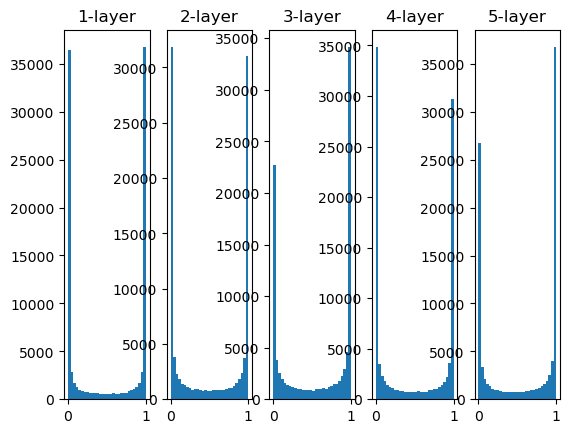

In [31]:
# 标准差为1
x = np.random.randn(1000, 100) # 1000个数据，参数为生成数组的形状，默认输出标准正态分布N(0,1)
node_num = 100        # 各隐藏层的节点（神经元）数
hidden_layer_size = 5 # 隐藏层有5层
activations = {}      # 激活值的结果保存在这里
for i in range(hidden_layer_size):
    if i != 0:
        x = activations[i-1]
    w = np.random.randn(node_num, node_num) * 1
    z = np.dot(x, w)
    a = sigmoid(z)   # sigmoid函数
    activations[i] = a

# 绘制直方图
for i, a in activations.items():
    plt.subplot(1, len(activations), i+1)
    plt.title(str(i+1) + "-layer")
    plt.hist(a.flatten(), 30, range=(0,1))
plt.show()

由图可知，使用标准正态分布时，各层的激活值呈偏向0和1的分布，由于sigmoid函数的反向传播需要将上游传来的梯度乘以y(1-y)，因此偏向0或1的数据分布会导致梯度的值急剧减小，最后消失。这个现象称为梯度消失（gradient vanishing）。

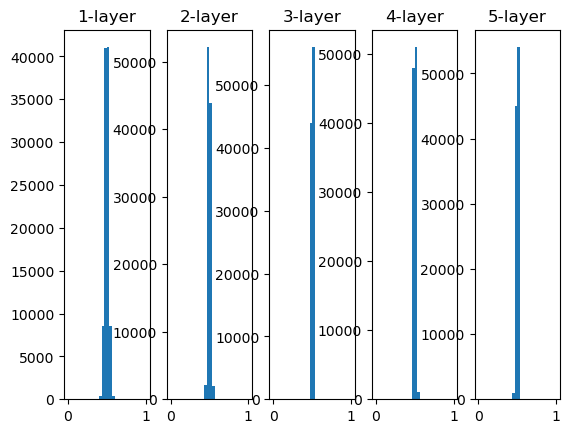

In [32]:
# 标准差为0.01
x = np.random.randn(1000, 100) # 1000个数据，参数为生成数组的形状，默认输出标准正态分布N(0,1)
node_num = 100        # 各隐藏层的节点（神经元）数
hidden_layer_size = 5 # 隐藏层有5层
activations = {}      # 激活值的结果保存在这里
for i in range(hidden_layer_size):
    if i != 0:
        x = activations[i-1]
    w = np.random.randn(node_num, node_num) * 0.01
    z = np.dot(x, w)
    a = sigmoid(z)   # sigmoid函数
    activations[i] = a

# 绘制直方图
for i, a in activations.items():
    plt.subplot(1, len(activations), i+1)
    plt.title(str(i+1) + "-layer")
    plt.hist(a.flatten(), 30, range=(0,1))
plt.show()

由图可知，使用标准差为0.01的正态分布时，各层的激活值集中在0.5附近，不会发生梯度消失的问题。但是，激活值的分布过于集中，会导致神经网络的表现力受限，学习无法顺利进行。

#### 5.2.1 Xavier初始值

Xavier和Yoshua于2010年的论文[《Understanding the difficulty of training deep feedforward neural networks》](https://proceedings.mlr.press/v9/glorot10a/glorot10a.pdf)提出了Xavier初始值。他们得出的结论是，如果前一层的节点数为n，则初始值使用标准差为$\frac{1}{\sqrt{n}}$的分布。

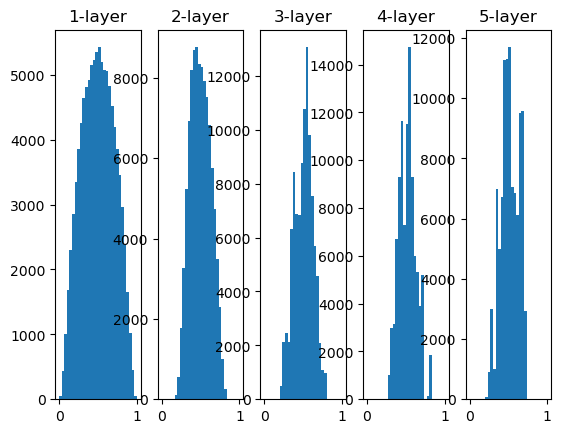

In [33]:
# Xavier初始值
x = np.random.randn(1000, 100) # 1000个数据，参数为生成数组的形状，默认输出标准正态分布N(0,1)
node_num = 100        # 各隐藏层的节点（神经元）数
hidden_layer_size = 5 # 隐藏层有5层
activations = {}      # 激活值的结果保存在这里
for i in range(hidden_layer_size):
    if i != 0:
        x = activations[i-1]
    w = np.random.randn(node_num, node_num) / np.sqrt(node_num)
    z = np.dot(x, w)
    a = sigmoid(z)   # sigmoid函数
    activations[i] = a

# 绘制直方图
for i, a in activations.items():
    plt.subplot(1, len(activations), i+1)
    plt.title(str(i+1) + "-layer")
    plt.hist(a.flatten(), 30, range=(0,1))
plt.show()

由图可知，相较于标准差0.01的正态分布，Xavier初始值呈现出了更有广度的分布，有望进行高效的学习。但后面层的分布呈歪斜的形状，如果用tanh函数代替sigmoid函数，会呈漂亮的吊钟型分布。

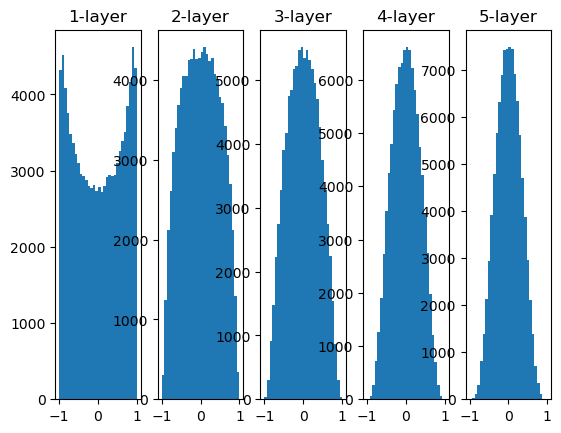

In [34]:
# Xavier初始值+tanh函数
x = np.random.randn(1000, 100) # 1000个数据，参数为生成数组的形状，默认输出标准正态分布N(0,1)
node_num = 100        # 各隐藏层的节点（神经元）数
hidden_layer_size = 5 # 隐藏层有5层
activations = {}      # 激活值的结果保存在这里
for i in range(hidden_layer_size):
    if i != 0:
        x = activations[i-1]
    w = np.random.randn(node_num, node_num) / np.sqrt(node_num)
    z = np.dot(x, w)
    a = np.tanh(z)   # tanh函数
    activations[i] = a

# 绘制直方图
for i, a in activations.items():
    plt.subplot(1, len(activations), i+1)
    plt.title(str(i+1) + "-layer")
    plt.hist(a.flatten(), 30, range=(-1,1))
plt.show()

#### 5.2.2 He初始值

当激活函数使用ReLU时，一般推荐使用ReLU专用的初始值，如Kaiming He等人在[《Delving Deep into Rectifiers》](https://www.cv-foundation.org/openaccess/content_iccv_2015/papers/He_Delving_Deep_into_ICCV_2015_paper.pdf)中推荐的He初始值。当前一层的节点数为n时，He初始值使用标准差为$\frac{2}{\sqrt{n}}$的正态分布。直观上可以解释为，因为ReLU的负值区域的值为0，为了使激活值的分布更有广度，所以需要2倍的系数。

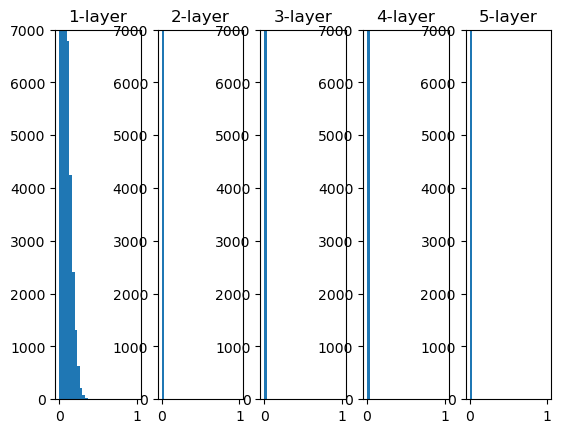

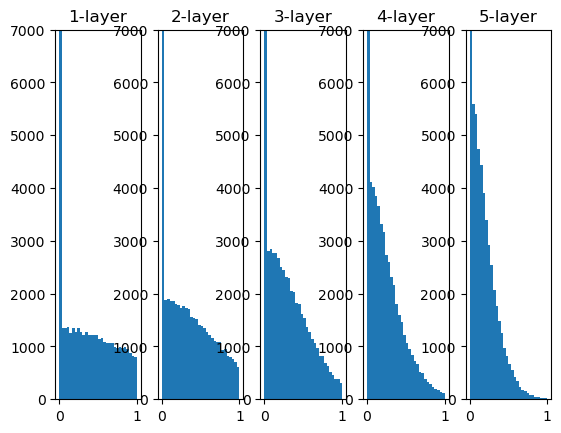

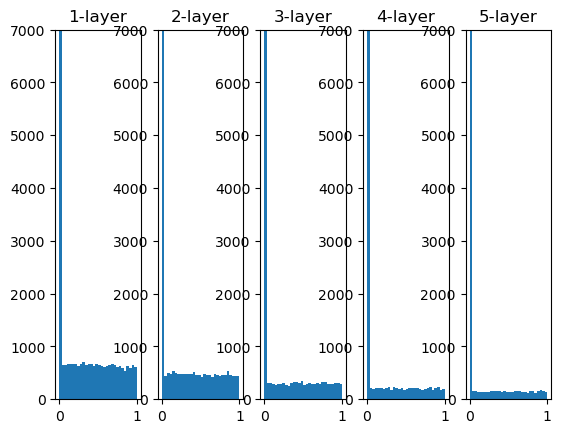

In [35]:
# 使用ReLU函数时N(0, 0.01), Xavier和He作为权重初始值的对比
import numpy as np
import matplotlib.pyplot as plt

def relu(x):
    return np.maximum(0, x)

def plot(w):
    x = np.random.randn(1000, 100)
    hidden_layer_size = 5
    activations = {}
    for i in range(hidden_layer_size):
        if i != 0:
            x = activations[i-1]
        z = np.dot(x, w)
        a = relu(z)
        activations[i] = a

    for i, a in activations.items():
        plt.subplot(1, len(activations), i+1)
        plt.title(str(i+1) + "-layer")
        plt.hist(a.flatten(), 30, range=(0,1))
        plt.ylim(0, 7000)
    plt.show()

node_num = 100
w1 = np.random.randn(node_num, node_num) * 0.01
w2 = np.random.randn(node_num, node_num) / np.sqrt(node_num)
w3 = np.random.randn(node_num, node_num) * 2 / np.sqrt(node_num)
plot(w1)
plot(w2)
plot(w3)

由图可知，当使用N(0, 0.01)时，各层的激活值非常小，因此反向传播时（ReLU函数反向传播看正向传播时输入，若输入大于零，则反向传播保持不变，若输入小于等于零，则停止传播），尽管ReLU函数保持梯度不变，但仿射层梯度会右乘权重矩阵的转置，而权重矩阵生成时由于乘了0.01，所以里面的每个值也都变为原来（约95%处于[-2, 2]）的0.01倍，导致每次反向传播经过仿射层时，梯度都会急剧变小，学习基本没有进展。

而使用Xavier初始值时，随着层的增多，分布偏向逐渐变大。当使用He初始值时，各层中分布的广度相同。

因此，当激活函数使用ReLU时，权重初始值使用He初始值，当激活函数为sigmoid或tanh等S型曲线函数时，初始值使用Xavier初始值。

### 5.3 批标准化

批标准化（Batch Normalization）的思路是调整各层激活值的分布，使其拥有适当的广度。具体来说，批标准化层首先将输入数据进行均值为0、方差为1的正规化，即$$\bm{\hat{x}}=\frac{\bm{x}-\bm{\mu}}{\sqrt{\sigma^2+\varepsilon}}\tag{5.3}$$，其中$\varepsilon$为微小值，防止出现除0。

接着，批标准化层会对正规化后的数据进行缩放和平移，即$$\bm{y}=\gamma\bm{\hat{x}}+\bm{\beta}\tag{5.4}$$，其中$\gamma$和$\bm{\beta}$是参数。初始$\gamma=1,\bm{\beta}=\bm{0}$，然后再通过学习调整到合适的值。

因此，批标准化可以推动学习的进行，并且使学习对权重初
始值变得鲁棒。

### 5.4 正则化

#### 5.4.1 过拟合

过拟合（overfitting）指模型在训练集上表现很好，但在测试集或新数据上表现变差，说明模型学习了训练数据中的噪声或偶然模式，泛化能力下降。

过拟合的原因主要有两个：
1. 模型过于复杂（参数太多）：模型容量远大于任务需求，容易拟合噪声。
2. 数据量太少：样本不足以代表真实分布，模型只能“记住”训练样本。

#### 5.4.2 权值衰减

权值衰减通过在学习的过程中对大的权重进行惩罚，来抑制过拟合，因为很多过拟合原本就是因为权重参数取值过大才发生的。权重过大之所以是导致过拟合的核心原因之一，主要是因为大权重赋予了模型极高的复杂度和对输入的极端敏感性，使其能够轻易地扭曲自己去迎合数据中的每一个噪点。

Frobenius范数：矩阵所有元素平方和的平方根，用于衡量矩阵整体“大小”或“能量”，记为$\lVert A\rVert_F$。

较为常用的方法是将损失函数加上$\frac{1}{2}\lambda\lVert A\rVert_F^2$，$\lambda$是控制正则化强度的超参数，$\lambda$越大，对大权重的惩罚越重。$\frac{1}{2}$是为了使求导结果更简洁。

#### 5.4.3 随机失活

随机失活（Dropout）是一种在训练神经网络时随机“失活”部分神经元的正则化方法，用于防止过拟合并提升模型泛化能力。训练时，随机选出隐藏层的神经元，然后将其删除，不再进行信号的传递。每传递一次数据，就会随机选择要删除的神经元。测试时，虽然会传递所有的神经元信号，但是对于各个神经元的输出，要乘上训练时的删除比例后再输出，以保证训练和测试时神经元的输出期望相同。这样，Dropout将集成学习（让多个模型单独进行学习，推理时再取多个模型的输出的平均值）的效果通过一个网络进行模拟。


In [36]:
class Dropout:
    def __init__(self, dropout_ratio=0.5):
        self.dropout_ratio = dropout_ratio
        self.mask = None
    def forward(self, x, train_flg=True):
        if train_flg:
            self.mask = np.random.rand(*x.shape) > self.dropout_ratio
            return x * self.mask
        else:
            return x * (1.0 - self.dropout_ratio)
    def backward(self, dout):
        return dout * self.mask

`np.random.rand(*x.shape)`会生成一个和x形状相同的随机数组，每个元素在[0,1)之间。`np.random.rand(*x.shape) > self.dropout_ratio`会生成一个和x形状相同的布尔数组，大约有50%的位置是True，50%的位置是False。测试时`train_flg=False`，把所有输出乘以保留概率`1.0 - self.dropout_ratio`。前向传播中被丢弃的神经元，反向传播时也不应该有梯度；前向传播中保留的神经元，反向传播时梯度正常传递。

### 5.5 超参数的验证

#### 5.5.1 验证数据

调整超参数时，必须使用专用的确认数据，称为验证数据（validation data）。

总结：训练数据用于参数（权重和偏置）的学习，验证数据用于超参数的性能评估。为了确认泛化能力，要在最后使用（比较理想的是只用一次）测试数据。

根据不同的数据集，有的会事先分成训练数据、验证数据、测试数据三部分，有的只分成训练数据和测试数据两部分，有的则不进行分割。在这种情况下，用户需要自行进行分割。常见比例约为训练集:验证集:测试集 = 8:1:1。

#### 5.5.2 超参数的最优化

步骤：
1. 设定超参数的大致范围，如10^-3到10^3；
2. 从设定的超参数范围中随机采样；
3. 使用步骤2中采样到的超参数值进行学习，通过验证数据评估识别精度（注意epoch要设置得很小，以加快搜索进度）；
4. 多次重复步骤2和步骤3，如100次，根据它们的识别精度的结果，缩小超参数的范围。

反复进行上述操作，不断缩小超参数的范围，在缩小到一定程度时，从该范围中选出一个超参数的值。这就是进行超参数的最优化的一种方法。

## 七、卷积神经网络

### 7.1 卷积层

#### 7.1.1 仿射层存在的问题

在仿射层中，需要将3维的输入数据拉平为1维数据，忽视数据的高维特征。图像通常是高、长、通道方向上的3维数据，3维形状中可能隐藏有值得提取的本质模式，而仿射层无法利用与形状相关的信息。但卷积层可以保持形状不变。当输入数据是图像时，卷积层会以3维数据的形式接收输入数据，并同样以3维数据的形式输出至下一层。

在卷积神经网络（CNN, Convolutional Neural Network）中，有时卷积层的输入数据被称为输入特征图（input feature map），输出数据被称为输出特征图（output feature map）。

#### 7.1.2 卷积

